In [1]:
import os
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [7]:
train_dir = "../data/balanced/train"
val_dir   = "../data/processed/val"
test_dir  = "../data/processed/test"

print("Train path:", train_dir, "| Exists:", os.path.exists(train_dir))
print("Val path:", val_dir, "| Exists:", os.path.exists(val_dir))
print("Test path:", test_dir, "| Exists:", os.path.exists(test_dir))

Train path: ../data/balanced/train | Exists: True
Val path: ../data/processed/val | Exists: True
Test path: ../data/processed/test | Exists: True


In [8]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms defined successfully.")

Transforms defined successfully.


In [9]:
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset   = datasets.ImageFolder(val_dir, transform=test_transform)
test_dataset  = datasets.ImageFolder(test_dir, transform=test_transform)

print("Train classes:", train_dataset.classes)
print("Val classes:", val_dataset.classes)
print("Test classes:", test_dataset.classes)

print("\nDataset sizes:")
print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

Train classes: ['ai_generated', 'deepfake', 'edited', 'real']
Val classes: ['ai_generated', 'deepfake', 'edited', 'real']
Test classes: ['ai_generated', 'deepfake', 'edited', 'real']

Dataset sizes:
Train: 1600
Val  : 3168
Test : 3165


In [10]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 50
Val batches: 99
Test batches: 99


In [11]:
class_names = train_dataset.classes
class_to_idx = train_dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}

print("Class to index mapping:")
for class_name, idx in class_to_idx.items():
    print(f"{class_name} -> {idx}")

Class to index mapping:
ai_generated -> 0
deepfake -> 1
edited -> 2
real -> 3


In [12]:
def get_class_counts(dataset):
    counts = {}
    for _, label in dataset.samples:
        counts[label] = counts.get(label, 0) + 1

    readable_counts = {idx_to_class[idx]: count for idx, count in counts.items()}
    return readable_counts

print("Train class counts:")
print(get_class_counts(train_dataset))

print("\nValidation class counts:")
print(get_class_counts(val_dataset))

print("\nTest class counts:")
print(get_class_counts(test_dataset))

Train class counts:
{'ai_generated': 400, 'deepfake': 400, 'edited': 400, 'real': 400}

Validation class counts:
{'ai_generated': 25, 'deepfake': 1582, 'edited': 39, 'real': 1522}

Test class counts:
{'ai_generated': 24, 'deepfake': 1580, 'edited': 38, 'real': 1523}


In [13]:
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

in_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(0.30),
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.20),
    nn.Linear(256, len(class_names))
)

model = model.to(device)

print("Model moved to:", device)
print("\nFinal classifier:")
print(model.classifier)

Model moved to: cuda

Final classifier:
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=256, out_features=4, bias=True)
)


In [17]:
from collections import Counter

labels = [label for _, label in train_dataset.samples]
counts = Counter(labels)

total_samples = len(labels)
num_classes = len(class_names)

class_weights = []

for i in range(num_classes):
    class_count = counts[i]
    weight = total_samples / (num_classes * class_count)
    class_weights.append(weight)

class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class Weights:", class_weights)

Class Weights: tensor([1., 1., 1., 1.], device='cuda:0')


In [15]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.ce = nn.CrossEntropyLoss(weight=alpha)

    def forward(self, inputs, targets):
        ce_loss = self.ce(inputs, targets)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss

In [16]:
criterion = FocalLoss(alpha=class_weights, gamma=2)

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2
)

print("Using Focal Loss + Class Weights")
print("Optimizer: AdamW")

Using Focal Loss + Class Weights
Optimizer: AdamW


In [18]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    running_corrects = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels)
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_corrects.double().item() / total

    return epoch_loss, epoch_acc

In [19]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    running_corrects = 0
    total = 0

    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels)
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = running_corrects.double().item() / total

    return epoch_loss, epoch_acc, all_labels, all_preds

In [21]:
num_epochs = 10

best_val_acc = 0.0
best_val_loss = float('inf')

best_acc_model_wts = copy.deepcopy(model.state_dict())
best_loss_model_wts = copy.deepcopy(model.state_dict())

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):
    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print("-" * 50)

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_acc_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), "best_acc_model.pth")
        print(" Best Accuracy Model Saved")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_loss_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), "best_loss_model.pth")
        print(" Best Loss Model Saved")

print("\nTraining complete.")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")
print(f"Lowest Validation Loss: {best_val_loss:.4f}")


Epoch [1/10]
--------------------------------------------------
Train Loss: 0.0097 | Train Acc: 0.9500
Val   Loss: 0.0088 | Val   Acc: 0.9426
 Best Accuracy Model Saved
 Best Loss Model Saved

Epoch [2/10]
--------------------------------------------------
Train Loss: 0.0059 | Train Acc: 0.9606
Val   Loss: 0.0061 | Val   Acc: 0.9441
 Best Accuracy Model Saved
 Best Loss Model Saved

Epoch [3/10]
--------------------------------------------------
Train Loss: 0.0035 | Train Acc: 0.9694
Val   Loss: 0.0052 | Val   Acc: 0.9451
 Best Accuracy Model Saved
 Best Loss Model Saved

Epoch [4/10]
--------------------------------------------------
Train Loss: 0.0026 | Train Acc: 0.9750
Val   Loss: 0.0054 | Val   Acc: 0.9457
 Best Accuracy Model Saved

Epoch [5/10]
--------------------------------------------------
Train Loss: 0.0027 | Train Acc: 0.9775
Val   Loss: 0.0046 | Val   Acc: 0.9479
 Best Accuracy Model Saved
 Best Loss Model Saved

Epoch [6/10]
--------------------------------------------

In [22]:
model.load_state_dict(best_acc_model_wts)
print("Loaded Best Accuracy Model")

model.load_state_dict(best_loss_model_wts)
print("Loaded Best Loss Model")

Loaded Best Accuracy Model
Loaded Best Loss Model


In [23]:
model.load_state_dict(best_acc_model_wts)
print("Loaded Best Accuracy Model for final evaluation.")

Loaded Best Accuracy Model for final evaluation.


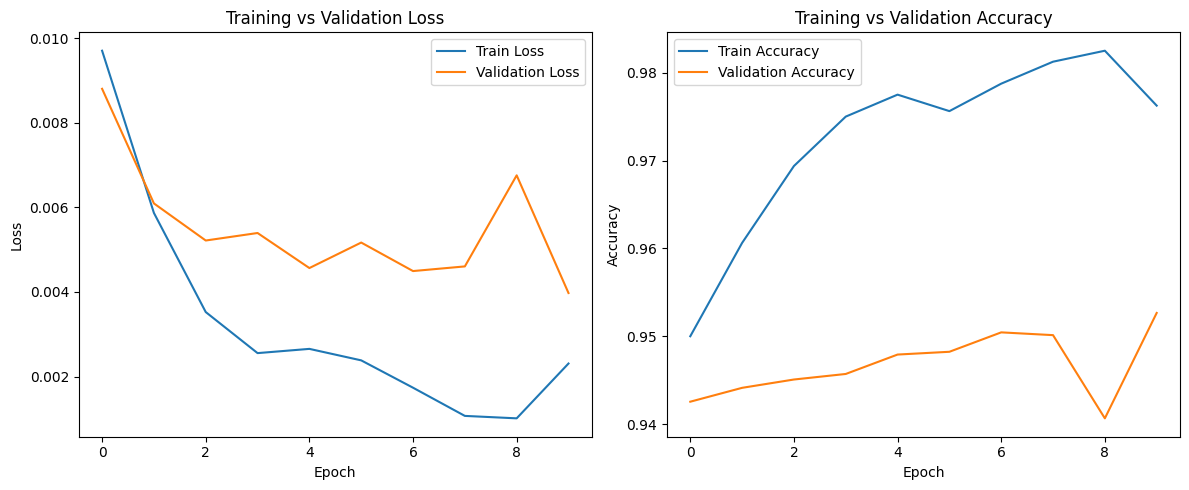

In [24]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
test_loss, test_acc, y_true, y_pred = evaluate(model, test_loader, criterion, device)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.0056
Test Accuracy: 0.9536


In [26]:
from sklearn.metrics import classification_report

print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

Classification Report:

              precision    recall  f1-score   support

ai_generated       0.73      0.79      0.76        24
    deepfake       0.96      0.96      0.96      1580
      edited       0.67      0.84      0.74        38
        real       0.96      0.95      0.96      1523

    accuracy                           0.95      3165
   macro avg       0.83      0.89      0.86      3165
weighted avg       0.95      0.95      0.95      3165



In [29]:
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("\nConfusion Matrix (Rows = Actual, Columns = Predicted):\n")
display(cm_df)


Confusion Matrix (Rows = Actual, Columns = Predicted):



,ai_generated,deepfake,edited,real
ai_generated,19,0,4,1
deepfake,0,1520,4,56
edited,5,0,32,1
real,2,66,8,1447


In [30]:
from collections import Counter

misclassified = []

for true, pred in zip(y_true, y_pred):
    if true != pred:
        misclassified.append((idx_to_class[true], idx_to_class[pred]))

mis_counts = Counter(misclassified)

print("Top misclassification pairs:\n")

for (true_label, pred_label), count in mis_counts.most_common():
    print(f"{true_label} → {pred_label}: {count}")

Top misclassification pairs:

real → deepfake: 66
deepfake → real: 56
real → edited: 8
edited → ai_generated: 5
ai_generated → edited: 4
deepfake → edited: 4
real → ai_generated: 2
ai_generated → real: 1
edited → real: 1


The primary misclassification occurs between "real" and "deepfake" classes, indicating high visual similarity and difficulty in detecting subtle manipulations. 

Secondary confusion is observed between "edited" and "ai_generated" classes due to overlapping synthetic characteristics. Overall, the model errors are structured and interpretable rather than random.